# SCIKIT-LEARN MASTERY — NOTEBOOK 9
## Chapters 46–52: Sample Weights (Deep Dive) → Feature Importance & Interpretability → Permutation Importance → Partial Dependence → Learning Curves → Validation Curves → Model Comparison Framework

Continuing directly from Notebook 8.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–45 *(Notebooks 1–8)*
- [x] Sample Weights (deep dive)
- [x] Feature Importance & Interpretability (overview)
- [x] Permutation Importance
- [x] Partial Dependence
- [x] Learning Curves
- [x] Validation Curves
- [x] Model Comparison Framework


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_regression
np.random.seed(42)


---
# CHAPTER 46 — SAMPLE WEIGHTS

## 1. Concept
`sample_weight` (introduced in Chapter 45 for class imbalance) is a genuinely general-purpose mechanism used across **training, scoring, and cross-validation** — worth its own focused chapter because it applies to far more situations than just imbalanced classes.

## 2. Where `sample_weight` Applies
| Context | What it changes |
|---|---|
| `model.fit(X, y, sample_weight=w)` | Each sample's contribution to the loss function during training is scaled by `w` |
| `metric_function(y_true, y_pred, sample_weight=w)` | Most `sklearn.metrics` functions accept this — the metric itself is computed as a weighted average |
| `cross_val_score(..., fit_params={"sample_weight": w})` | Propagates weights correctly through cross-validation folds (each fold gets the corresponding weight subset automatically) |

## 3. Beyond Class Imbalance — Other Legitimate Uses


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# SCENARIO: predicting sales, where RECENT data should matter more than old data
# (the underlying relationship may have drifted -- exactly the Matplotlib course's Ch 67 data drift concern)
np.random.seed(46)
n = 300
days_ago = np.arange(n)[::-1]   # 0 = most recent, n-1 = oldest
X_time = np.random.randn(n, 3)
true_coef_recent = np.array([5, -2, 3])
true_coef_old = np.array([1, 4, -1])   # the relationship WAS different in the past
blend = np.clip(1 - days_ago / n, 0, 1)   # 1.0 = fully "recent" relationship, 0.0 = fully "old" relationship
y_time = np.array([
    X_time[i] @ (blend[i] * true_coef_recent + (1 - blend[i]) * true_coef_old) + np.random.normal(0, 1)
    for i in range(n)
])

X_time_train, X_time_test, y_time_train, y_time_test, days_train, days_test = train_test_split(
    X_time, y_time, days_ago, test_size=0.2, random_state=42, shuffle=False   # shuffle=False -- keep temporal order
)

# Weight recent samples MORE heavily -- an exponential recency weighting
recency_weights = np.exp(-days_train / 100)

model_unweighted = LinearRegression().fit(X_time_train, y_time_train)
model_weighted = LinearRegression().fit(X_time_train, y_time_train, sample_weight=recency_weights)

mae_unweighted = mean_absolute_error(y_time_test, model_unweighted.predict(X_time_test))
mae_weighted = mean_absolute_error(y_time_test, model_weighted.predict(X_time_test))

print(f"Unweighted MAE (treats all history equally):     {mae_unweighted:.3f}")
print(f"Recency-weighted MAE (recent data matters more):  {mae_weighted:.3f}")


Unweighted MAE (treats all history equally):     3.928
Recency-weighted MAE (recent data matters more):  2.792


### Line-by-Line Explanation
- `recency_weights = np.exp(-days_train / 100)` — an exponential decay: the most recent sample (`days_ago=0`) gets weight `1.0`, and weight shrinks exponentially for older samples — a standard, simple way to encode "recent data is more representative of the current relationship" directly into training, without discarding old data entirely (as a hard cutoff/window would) or pretending it's equally relevant (as unweighted training does).
- Since the underlying relationship genuinely drifted in this synthetic setup (`blend` interpolates between two different true coefficient sets over time), recency weighting should measurably improve test performance — the test set represents the *most recent* period, so a model that weighted recent training data more heavily is better matched to what it's being evaluated against.

### Weighted Evaluation Metrics


In [3]:
# sample_weight ALSO applies at evaluation time -- e.g., weighting business-critical customers more
# heavily in a reported error metric, even if they weren't weighted specially during TRAINING
important_customer_weight = np.where(np.arange(len(y_time_test)) % 5 == 0, 3.0, 1.0)  # every 5th "customer" is high-value

mae_plain = mean_absolute_error(y_time_test, model_weighted.predict(X_time_test))
mae_business_weighted = mean_absolute_error(y_time_test, model_weighted.predict(X_time_test), sample_weight=important_customer_weight)

print(f"Plain MAE (every test sample equal):              {mae_plain:.3f}")
print(f"Business-weighted MAE (high-value customers 3x):  {mae_business_weighted:.3f}")
print("\nThese can genuinely differ -- if the model happens to be LESS accurate specifically for")
print("high-value customers, business-weighted MAE will be noticeably worse than the plain average,")
print("directly surfacing a business-relevant blind spot that an unweighted metric would hide.")


Plain MAE (every test sample equal):              2.792
Business-weighted MAE (high-value customers 3x):  2.868

These can genuinely differ -- if the model happens to be LESS accurate specifically for
high-value customers, business-weighted MAE will be noticeably worse than the plain average,
directly surfacing a business-relevant blind spot that an unweighted metric would hide.


### Common Mistakes
- Only ever thinking of `sample_weight` in the context of class imbalance — it's a general tool applicable to recency weighting, business-importance weighting, survey/sampling-design weighting, and more.
- Weighting during training but forgetting metrics can *also* be weighted, missing the opportunity to report a business-relevant (not just statistically-representative) evaluation number.
- Not propagating `sample_weight` correctly through `cross_val_score`/`GridSearchCV` (via `fit_params`) when cross-validating a weighted training scheme — each fold needs the correctly-indexed weight subset, not the full original array.

### Interview Insight
**Q: Beyond class imbalance, name a legitimate business scenario for using `sample_weight`.**
A: Recency weighting in a business context where the underlying relationship may drift over time (e.g., customer behavior, pricing sensitivity) — weighting recent training samples more heavily than old ones lets the model adapt to the current relationship without completely discarding older, still somewhat-relevant data via a hard cutoff. Another example: weighting samples by their real-world business importance at evaluation time (e.g., reporting error specifically weighted toward high-value customers), surfacing whether the model performs adequately where it matters most, which an unweighted average metric could otherwise mask.

### Quiz (Chapter 46)
1. Name three distinct contexts where `sample_weight` applies (training, metrics, cross-validation).
2. Give a legitimate `sample_weight` use case beyond class imbalance.
3. Why might a business-weighted metric diverge meaningfully from a plain unweighted metric?


---
# CHAPTER 47 — FEATURE IMPORTANCE AND INTERPRETABILITY (OVERVIEW)

## 1. Concept
"Feature importance" is not one single, universally-defined concept — different techniques measure genuinely different things, and conflating them is a common, consequential mistake. This chapter maps the landscape; Chapters 48–49 go deep on the two most important, model-agnostic techniques.

## 2. The Landscape
| Technique | What it measures | Model-agnostic? | Direction of effect? |
|---|---|---|---|
| **Coefficients** (linear models) | Change in prediction per unit change in a (scaled) feature | No — linear models only | Yes (sign shows direction) |
| **`feature_importances_`** (trees/ensembles) | How much a feature reduced impurity/error across all splits | No — tree-based models only | No — magnitude only, no direction |
| **Permutation Importance** | Performance drop when a feature is randomly shuffled | **Yes** — works for any fitted model | No — magnitude only |
| **Partial Dependence** | How the prediction changes as one feature varies, averaging over all others | **Yes** | Yes — shows the full functional shape |
| **SHAP** (external library, mentioned conceptually) | Game-theoretic per-prediction feature attribution, with strong theoretical guarantees | **Yes** | Yes — per-individual-prediction direction and magnitude |


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

X_fi, y_fi = make_classification(n_samples=500, n_features=6, n_informative=4, random_state=42)
feature_names_fi = [f"feat_{i}" for i in range(6)]
X_fi_scaled = StandardScaler().fit_transform(X_fi)

lr_fi = LogisticRegression(max_iter=1000).fit(X_fi_scaled, y_fi)
rf_fi = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_fi_scaled, y_fi)

comparison_fi = pd.DataFrame({
    "feature": feature_names_fi,
    "LR coefficient (signed)": lr_fi.coef_[0],
    "RF feature_importances_ (unsigned)": rf_fi.feature_importances_,
})
print(comparison_fi.round(3))


  feature  LR coefficient (signed)  RF feature_importances_ (unsigned)
0  feat_0                   -0.430                               0.119
1  feat_1                   -0.166                               0.188
2  feat_2                    0.369                               0.171
3  feat_3                    0.037                               0.137
4  feat_4                    0.666                               0.198
5  feat_5                    0.470                               0.188


### Interpretation
Note the LR coefficients carry a **sign** (direction: does the feature push toward class 0 or class 1?) while RF's `feature_importances_` are strictly **non-negative** (magnitude/usefulness only — a feature could be very important while the *relationship* is genuinely non-monotonic or non-linear, which a single unsigned number can't capture at all). This is precisely why "Feature X has high importance" is an incomplete statement without also specifying *which* importance technique produced that number and what it actually measures.

### Common Mistakes
- Directly comparing a linear model's coefficient magnitude to a tree ensemble's `feature_importances_` as if they were the same kind of number — they're computed via completely different mechanisms and aren't on a comparable scale or interpretation.
- Treating any of these techniques as revealing **causation** — every one of them describes an association pattern the specific fitted model learned, not a causal claim about the real world (the exact caveat from the Matplotlib course's Chapter 45, now specifically relevant to every technique in this chapter).
- Not realizing `feature_importances_` for tree models has the same high-cardinality bias flagged in the Matplotlib course's Chapter 59 — permutation importance (Chapter 48) is the standard, more robust remedy.

### Interview Insight
**Q: A linear model's coefficient for "income" is 0.8, and a Random Forest's `feature_importances_` for "income" is 0.15. Can you directly compare these two numbers to judge which model finds income more important?**
A: No — these are fundamentally different quantities computed via different mechanisms. The linear model's coefficient reflects the (scaled) change in log-odds per unit change in income, holding the linear model's other coefficients fixed, and can be directly interpreted with a sign showing direction. Random Forest's `feature_importances_` reflects a normalized measure of how much splitting on income reduced impurity across all trees, is strictly non-negative, and has no direct interpretation as "log-odds per unit change." They're not on the same scale and shouldn't be compared numerically — at most, you might informally compare their *relative rank* among each model's own features.

### Quiz (Chapter 47)
1. Name the five interpretability techniques covered in this chapter's landscape table.
2. Which of these techniques are model-agnostic (work for ANY fitted model)?
3. Why can't feature importance ever be treated as proof of causation?


---
# CHAPTER 48 — PERMUTATION IMPORTANCE

## 1. Concept — The Algorithm, Precisely
```
1. Compute the model's baseline score on (X, y).
2. For each feature, one at a time:
   a. Randomly SHUFFLE that feature's values across all samples
      (breaking its relationship with y, while leaving every OTHER
       feature and the target completely unchanged).
   b. Recompute the model's score on this shuffled data.
   c. Importance = baseline_score - shuffled_score
      (a bigger drop = the model relied on that feature more).
3. Repeat multiple times (different random shuffles) and average,
   to get a stable estimate plus a measure of variability.
```

This is **model-agnostic** — it works identically for a linear model, a tree ensemble, an SVM, or literally any fitted estimator with a `.score()` method, since it only ever probes the model from the outside (via shuffled inputs and outputs), never inspecting its internals.


In [5]:
from sklearn.inspection import permutation_importance
from sklearn.svm import SVC

# Use SVC specifically -- it has NO native feature_importances_ or interpretable coefficients (for non-linear kernels)
svc_pi = SVC().fit(X_fi_scaled, y_fi)

perm_result = permutation_importance(svc_pi, X_fi_scaled, y_fi, n_repeats=30, random_state=42, scoring="accuracy")

perm_df = pd.DataFrame({
    "feature": feature_names_fi,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)
print(perm_df.round(4))


  feature  importance_mean  importance_std
4  feat_4           0.1464          0.0160
2  feat_2           0.1289          0.0144
1  feat_1           0.1037          0.0131
0  feat_0           0.0541          0.0105
5  feat_5           0.0473          0.0098
3  feat_3           0.0320          0.0086


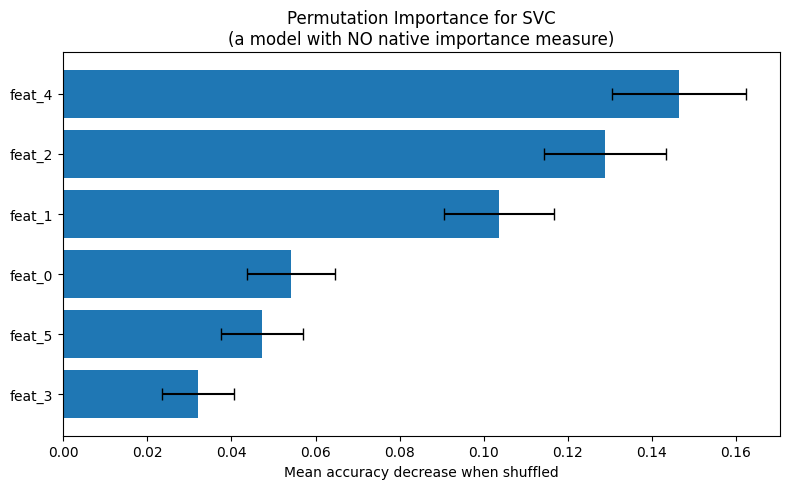

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
order = np.argsort(perm_result.importances_mean)
ax.barh(np.array(feature_names_fi)[order], perm_result.importances_mean[order],
        xerr=perm_result.importances_std[order], color="tab:blue", capsize=4)
ax.set_xlabel("Mean accuracy decrease when shuffled")
ax.set_title("Permutation Importance for SVC\n(a model with NO native importance measure)")
plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `n_repeats=30` — the shuffle is random, so a single shuffle's result is noisy; repeating 30 times and averaging (plus reporting `importances_std`) gives both a stable estimate and a genuine measure of how *reliable* that estimate is — a feature whose importance has a large std relative to its mean is a much weaker signal than one with a small std.
- `scoring="accuracy"` — permutation importance works with **any** scorer, not just accuracy; using `scoring="roc_auc"` or a custom business-cost scorer (Chapter 27) would measure "importance for that specific objective," which can genuinely differ from "importance for accuracy" — worth choosing deliberately to match what you actually care about.
- This example deliberately uses `SVC`, which has **no** `feature_importances_` and no directly interpretable coefficients for non-linear kernels — permutation importance is often the *only* viable interpretability technique for such models.

### Permutation Importance's Known Limitation: Correlated Features


In [7]:
# Create a feature that's a near-duplicate of an existing one, to demonstrate the correlated-feature problem
X_corr = np.column_stack([X_fi_scaled, X_fi_scaled[:, 0] + np.random.normal(0, 0.05, len(X_fi_scaled))])
feature_names_corr = feature_names_fi + ["feat_0_duplicate"]

rf_corr = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_corr, y_fi)
perm_corr = permutation_importance(rf_corr, X_corr, y_fi, n_repeats=20, random_state=42)

corr_df = pd.DataFrame({"feature": feature_names_corr, "importance": perm_corr.importances_mean}).sort_values("importance", ascending=False)
print(corr_df.round(4))
print("\nfeat_0 and feat_0_duplicate now likely each show LOWER individual importance than")
print("feat_0 showed ALONE (before duplication) -- because shuffling just ONE of a pair of")
print("correlated features barely hurts the model (the OTHER, still-intact copy still carries")
print("nearly the same information). This UNDERSTATES the true combined importance of that signal.")


            feature  importance
4            feat_4      0.1147
1            feat_1      0.0762
5            feat_5      0.0591
2            feat_2      0.0551
3            feat_3      0.0209
0            feat_0      0.0091
6  feat_0_duplicate      0.0066

feat_0 and feat_0_duplicate now likely each show LOWER individual importance than
feat_0 showed ALONE (before duplication) -- because shuffling just ONE of a pair of
correlated features barely hurts the model (the OTHER, still-intact copy still carries
nearly the same information). This UNDERSTATES the true combined importance of that signal.


### Internal Working / Limitation
When two features are highly correlated, shuffling **either one alone** barely degrades the model — the model can still effectively use the *other*, unshuffled, near-duplicate feature to recover most of the same information. This causes permutation importance to systematically **understate** the true combined importance of correlated feature groups, splitting what should be one strong importance signal across both features, each looking individually weaker than the underlying signal actually is. This is a genuine, well-documented limitation — not a bug, but an important interpretive caveat.

### Common Mistakes
- Not repeating shuffles enough (`n_repeats` too low) — produces a noisy, unreliable importance estimate; always check `importances_std` alongside the mean.
- Computing permutation importance on the **training set** rather than a held-out set — like any evaluation, computing it on training data can reflect overfitting-driven "importance" (the model exploiting noise it memorized) rather than genuine generalizable importance; a validation/test set is generally more meaningful here.
- Interpreting a low permutation importance for a feature as "genuinely useless" without checking for correlated features that might be diluting its apparent individual importance.

### Interview Insight
**Q: Two features, A and B, are highly correlated and both genuinely predictive. Permutation importance shows both with only moderate individual importance, lower than you'd expect. What's happening?**
A: Permutation importance shuffles one feature at a time — when A and B are highly correlated, shuffling just A doesn't hurt the model much, because B (still intact) carries nearly the same information A would have provided. The same happens when shuffling B alone. This causes the true combined predictive signal to be split and understated across both features individually, even though together they're genuinely important. This is a known limitation of permutation importance (and, similarly, of tree-based `feature_importances_`) — grouping correlated features together and measuring their combined importance (shuffling the group jointly), or using a technique less sensitive to this like SHAP's more principled attribution, are the standard remedies.

### Quiz (Chapter 48)
1. Walk through permutation importance's algorithm from memory, step by step.
2. Why must the shuffle be repeated multiple times rather than done once?
3. Why does permutation importance understate the importance of correlated feature groups?
4. Why is permutation importance considered model-agnostic when `feature_importances_` is not?


---
# CHAPTER 49 — PARTIAL DEPENDENCE

## 1. Concept
While permutation importance answers "how much does this feature matter overall," Partial Dependence answers a richer question: "**what is the shape** of the relationship between this feature and the prediction, on average, across the dataset?" — directly revealing non-linear effects that a single importance number cannot show.

## 2. `PartialDependenceDisplay`


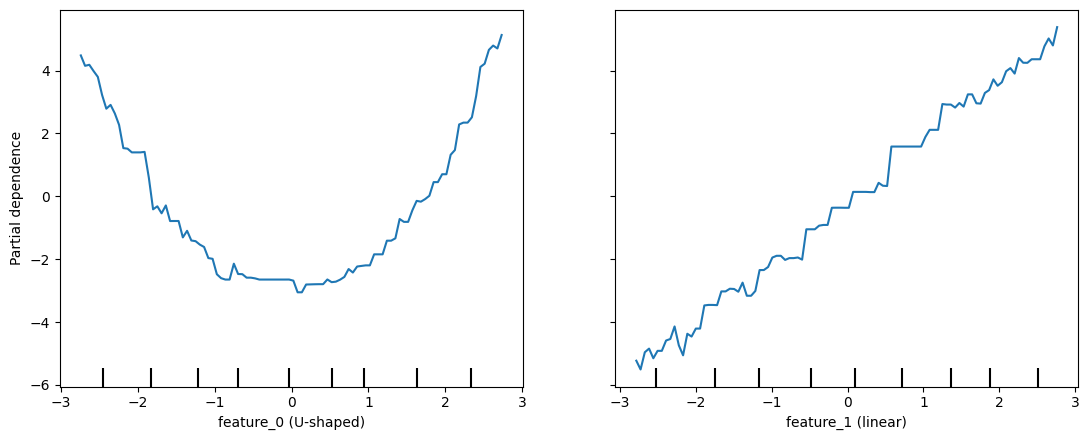

In [8]:
from sklearn.inspection import PartialDependenceDisplay
from sklearn.ensemble import GradientBoostingRegressor

# Build data with a GENUINELY non-linear (U-shaped) relationship between one feature and the target
np.random.seed(49)
n_pd = 500
X_pd = np.random.uniform(-3, 3, (n_pd, 3))
y_pd = X_pd[:, 0] ** 2 + X_pd[:, 1] * 2 + np.random.normal(0, 1, n_pd)   # feature 0: U-shaped; feature 1: linear

gbr_pd = GradientBoostingRegressor(n_estimators=200, max_depth=3, random_state=42).fit(X_pd, y_pd)

fig, ax = plt.subplots(figsize=(11, 4.5))
PartialDependenceDisplay.from_estimator(gbr_pd, X_pd, features=[0, 1], ax=ax,
                                          feature_names=["feature_0 (U-shaped)", "feature_1 (linear)"])
plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `PartialDependenceDisplay.from_estimator(model, X, features=[0, 1])` — for each listed feature, it (1) takes a grid of values spanning that feature's observed range, (2) for each grid value, sets **every sample's** value of that feature to the grid value while keeping all other features at their real, original values, (3) predicts on this modified dataset and averages the predictions, producing one point on the curve, and repeats across the full grid.
- The resulting curve for `feature_0` should visibly show the genuine **U-shape** — directly recovering the true underlying relationship, something no single importance number (permutation or otherwise) could reveal, since importance only tells you magnitude, never shape.
- `feature_1`'s curve should look roughly linear/monotonic, matching its true linear relationship with the target.

## 3. Individual Conditional Expectation (ICE) — Seeing Individual-Sample Variation


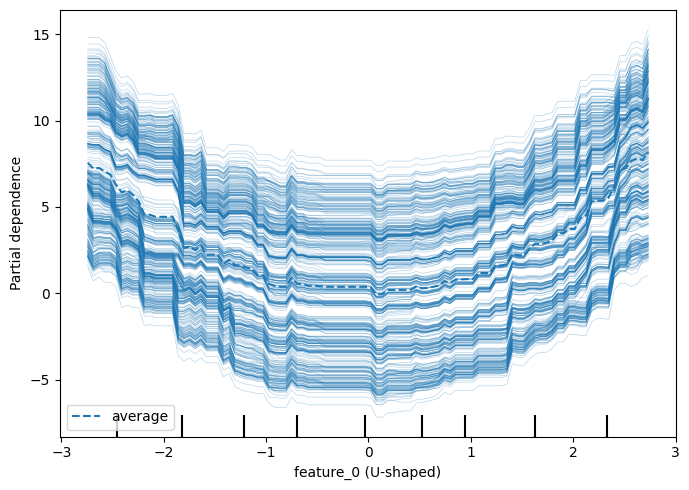

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
PartialDependenceDisplay.from_estimator(
    gbr_pd, X_pd, features=[0], kind="both",   # "both" = show PDP average line AND individual ICE lines
    ax=ax, feature_names=["feature_0 (U-shaped)", "feature_1"],
)
plt.tight_layout()
plt.show()


### Interpretation
`kind="both"` overlays thin individual-sample **ICE curves** (Individual Conditional Expectation — the same "vary this feature, hold others fixed" computation, but per-sample rather than averaged) beneath the thick average PDP line. If the ICE curves are all roughly parallel to each other and to the average PDP line, the relationship is consistent across the dataset (no meaningful interaction effects with other features). If ICE curves **diverge substantially** from each other, that's a direct visual signal that this feature's effect on the prediction genuinely *depends on other features' values* — an interaction effect the single averaged PDP line would completely hide.

### Common Mistakes
- Interpreting Partial Dependence as showing a **causal** relationship — it shows what the fitted *model* predicts would happen if a feature were changed, holding others fixed in the specific "average over the dataset" sense described above; this is a description of the model's learned behavior, not a controlled experiment establishing real-world causation.
- Only ever looking at the averaged PDP curve and never checking ICE — can miss important interaction effects where the average shape masks substantial disagreement between individual samples' actual curves.
- Computing PDP for a feature that's highly correlated with another feature — the "hold all other features at their real observed values" step can produce unrealistic, out-of-distribution combinations (e.g., setting "square footage" to a very high grid value while "number of rooms" stays at its original, small real value) — a genuine known limitation, for which SHAP-based alternatives (mentioned conceptually in Chapter 47) offer more robust handling.

### Interview Insight
**Q: What does Partial Dependence tell you that permutation importance does not?**
A: Permutation importance gives a single scalar: how much the model's overall performance degrades if this feature is randomized — a measure of magnitude only. Partial Dependence instead shows the actual **shape** of the relationship between a feature and the model's predictions, averaged across the dataset — revealing whether the effect is linear, U-shaped, monotonic-but-nonlinear, has a threshold, etc. Permutation importance tells you *how much* a feature matters; Partial Dependence tells you *how* it matters, in what direction and functional form, which is often far more actionable (e.g., revealing an optimal "sweet spot" value for a business-controllable feature, not just confirming the feature matters).

### Quiz (Chapter 49)
1. Walk through how a single point on a Partial Dependence curve is computed.
2. What does `kind="both"` add, and what does substantial divergence among ICE curves indicate?
3. Why should Partial Dependence never be interpreted as demonstrating causation?
4. What's a known limitation of Partial Dependence when features are highly correlated?


---
# CHAPTER 50 — LEARNING CURVES

## 1. Concept
*(Directly parallels the Matplotlib course's learning-curve chapter — here focused on the Scikit-learn API mechanics.)* `learning_curve()`/`LearningCurveDisplay` plot training and validation score against **training set size**, diagnosing whether more data would help (high variance) or not (high bias).


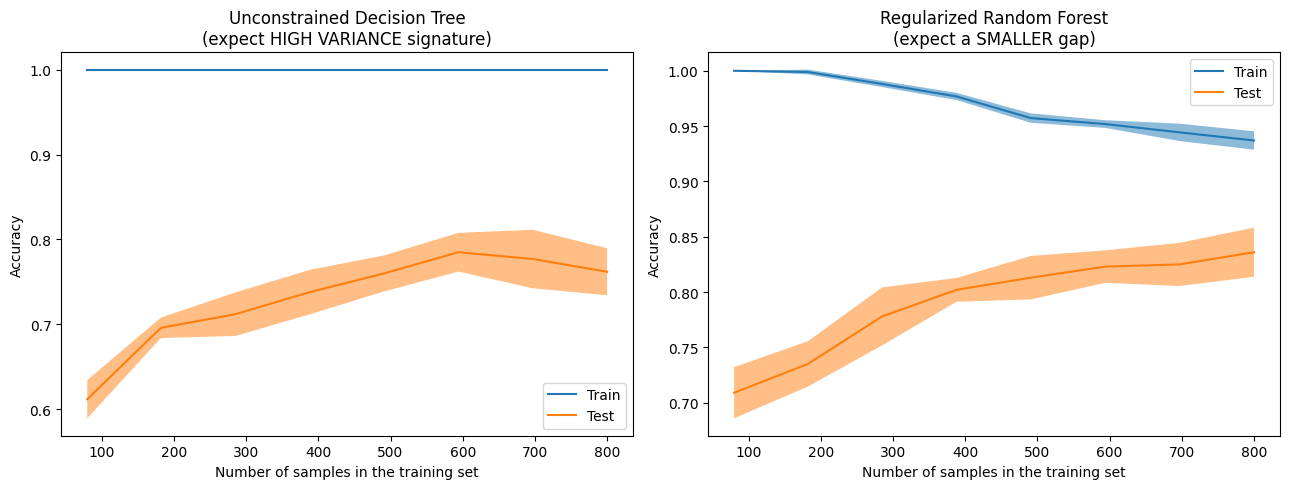

In [10]:
from sklearn.model_selection import learning_curve, LearningCurveDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

X_lc, y_lc = make_classification(n_samples=1000, n_features=15, n_informative=8, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# A DEEP, unconstrained tree -- expect a classic HIGH VARIANCE signature (large train-val gap)
LearningCurveDisplay.from_estimator(
    DecisionTreeClassifier(random_state=42), X_lc, y_lc, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8), ax=axes[0], score_name="Accuracy",
)
axes[0].set_title("Unconstrained Decision Tree\n(expect HIGH VARIANCE signature)")

# A well-regularized Random Forest -- expect the gap to be much smaller
LearningCurveDisplay.from_estimator(
    RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42), X_lc, y_lc, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8), ax=axes[1], score_name="Accuracy",
)
axes[1].set_title("Regularized Random Forest\n(expect a SMALLER gap)")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `LearningCurveDisplay.from_estimator(...)` — Scikit-learn's newer, dedicated display class wraps `learning_curve()`'s underlying computation and plotting into one call, directly analogous to `RocCurveDisplay`/`PrecisionRecallDisplay` from Chapter 29 — the same "compute + plot in one line" convenience pattern applied to yet another diagnostic.
- The unconstrained Decision Tree should show training accuracy staying near-perfect (it can memorize whatever training data it's given, regardless of size) while validation accuracy lags meaningfully behind — the classic overfitting/high-variance signature; the gap's *persistence* even at the largest training size is the signal that more data alone likely wouldn't fully close it (the model's fundamental tendency to overfit needs to be addressed directly, e.g., via `max_depth`, not just more data).
- The regularized Random Forest should show a visibly smaller train-validation gap — its constraints (`max_depth=6`, ensemble averaging) directly reduce the overfitting that produces this gap in the first place.

### Common Mistakes
- Concluding "we need more data" purely from a learning curve where the gap is already small/plateaued — misreads the diagnostic; a small, already-converged gap suggests more data of the *same kind* likely won't help much (the classic Matplotlib-course Chapter 62 lesson, directly relevant here too).
- Comparing two different models' learning curves at different `cv` values or different `train_sizes` grids — makes the comparison less directly meaningful; hold these constant across models being compared, as done above.

### Interview Insight
**Q: An unconstrained Decision Tree's learning curve shows a persistent large train-validation gap even at the maximum available training size. What does this tell you, and what would you try instead of collecting more data?**
A: A persistent gap at maximum training size suggests the model's tendency to overfit is fundamental to its current configuration, not simply a symptom of insufficient data — more data of the same kind is unlikely to close this gap on its own. The more direct fix is to constrain the model's complexity (e.g., `max_depth`, `min_samples_leaf`) or switch to an ensemble method (Random Forest, which averages many trees to reduce exactly this kind of variance) — addressing the root cause (excessive model flexibility relative to the signal-to-noise ratio in the data) rather than assuming the fix is more data.

### Quiz (Chapter 50)
1. What does `LearningCurveDisplay.from_estimator()` wrap and simplify?
2. Why does an unconstrained Decision Tree typically show a persistent, large train-validation gap?
3. What specific fix does that persistent-gap signature suggest, versus what "more data would help" would suggest?


---
# CHAPTER 51 — VALIDATION CURVES

## 1. Concept
`validation_curve()`/`ValidationCurveDisplay` sweep a **single hyperparameter** (x-axis) against training and validation score — directly distinguishing this from Chapter 50's learning curve (x-axis: training set size). This chapter builds a systematic sweep across several of the hyperparameters introduced across earlier model chapters.


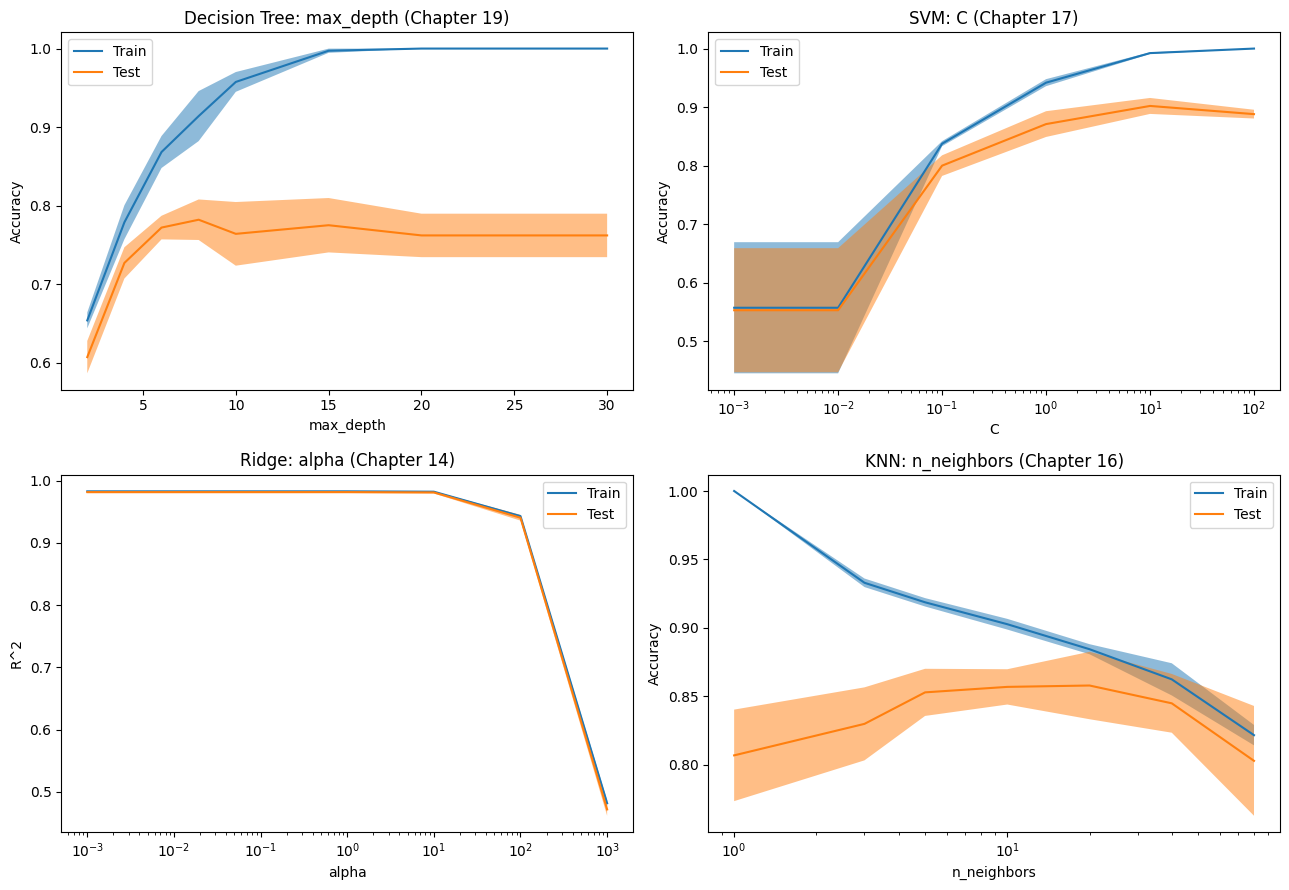

In [11]:
from sklearn.model_selection import ValidationCurveDisplay

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# max_depth for a Decision Tree
ValidationCurveDisplay.from_estimator(
    DecisionTreeClassifier(random_state=42), X_lc, y_lc,
    param_name="max_depth", param_range=[2, 4, 6, 8, 10, 15, 20, 30],
    cv=5, ax=axes[0, 0], score_name="Accuracy",
)
axes[0, 0].set_title("Decision Tree: max_depth (Chapter 19)")

# C for SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
X_lc_scaled = StandardScaler().fit_transform(X_lc)
ValidationCurveDisplay.from_estimator(
    SVC(), X_lc_scaled, y_lc,
    param_name="C", param_range=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5, ax=axes[0, 1], score_name="Accuracy",
)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("SVM: C (Chapter 17)")

# alpha for Ridge (regression -- using R^2 by default)
from sklearn.linear_model import Ridge
X_reg_vc, y_reg_vc = make_regression(n_samples=500, n_features=10, noise=20, random_state=42)
ValidationCurveDisplay.from_estimator(
    Ridge(), X_reg_vc, y_reg_vc,
    param_name="alpha", param_range=[0.001, 0.01, 0.1, 1, 10, 100, 1000],
    cv=5, ax=axes[1, 0], score_name="R^2",
)
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("Ridge: alpha (Chapter 14)")

# n_neighbors for KNN
from sklearn.neighbors import KNeighborsClassifier
ValidationCurveDisplay.from_estimator(
    KNeighborsClassifier(), X_lc_scaled, y_lc,
    param_name="n_neighbors", param_range=[1, 3, 5, 10, 20, 40, 80],
    cv=5, ax=axes[1, 1], score_name="Accuracy",
)
axes[1, 1].set_title("KNN: n_neighbors (Chapter 16)")

plt.tight_layout()
plt.show()


### Interpretation, Panel by Panel
- **Decision Tree `max_depth`**: training accuracy should climb toward 1.0 as depth increases (deeper trees can always fit training data better); validation accuracy should rise then plateau/decline — the point where they diverge marks the overfitting onset, directly confirming Chapter 19's constrained-tree recommendation empirically.
- **SVM `C`**: on a log scale, expect low `C` (strong regularization/wide margin) to underfit and high `C` to eventually overfit — confirming Chapter 17's `C` discussion with an actual measured curve rather than just the conceptual explanation.
- **Ridge `alpha`**: expect a similar shape — very high `alpha` over-shrinks coefficients toward zero (underfitting), very low `alpha` approaches unregularized `LinearRegression`'s behavior.
- **KNN `n_neighbors`**: expect small `k` to show high training accuracy but weaker validation accuracy (overfitting to individual neighbors), and very large `k` to underfit both — directly confirming Chapter 16's boundary visualization with a numeric curve.

Every one of these curves is the **empirical confirmation** of a conceptual point made when each algorithm was first introduced — this chapter's real value is proving those earlier conceptual claims with actual measured data, not introducing new theory.

### Common Mistakes
- Tuning a hyperparameter using a validation curve on a **linear** x-axis when the parameter's meaningful range spans multiple orders of magnitude (like `C`/`alpha`) — always use `ax.set_xscale("log")` for such parameters, exactly as done above, or the curve's shape becomes hard to read.
- Treating a validation curve's single-parameter sweep as equivalent to full hyperparameter tuning — it holds every *other* hyperparameter fixed at its default, which can miss interactions between parameters that `GridSearchCV`'s joint search (Chapter 25) would properly explore.

### Interview Insight
**Q: How does a validation curve differ from full hyperparameter tuning via `GridSearchCV`, and when would you use each?**
A: A validation curve sweeps exactly **one** hyperparameter while holding all others fixed, producing a clear visual diagnostic of that single parameter's individual bias-variance tradeoff — genuinely useful for building intuition about a specific parameter's behavior and roughly bounding a sensible search range. `GridSearchCV` jointly searches multiple hyperparameters simultaneously, correctly capturing interactions between them (e.g., the best `max_depth` might depend on `min_samples_leaf`'s value) that a series of independent single-parameter validation curves would miss. In practice: use validation curves for exploratory understanding and to narrow each parameter's search range, then use `GridSearchCV`/`RandomizedSearchCV` for the actual final joint tuning.

### Quiz (Chapter 51)
1. What's the key structural difference between a validation curve (this chapter) and a learning curve (Chapter 50)?
2. Why should `C`/`alpha`-style parameters usually be swept on a log-scaled x-axis?
3. Why doesn't a series of individual validation curves substitute for `GridSearchCV`'s joint search?


---
# CHAPTER 52 — MODEL COMPARISON FRAMEWORK

## 1. Concept
This chapter builds a genuinely **reusable, fair comparison framework** — every model evaluated with identical preprocessing, identical cross-validation folds, identical metrics, and identical random seeds — directly formalizing the "quick baseline scan" pattern first introduced informally in Chapter 13.


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold
import time

def compare_models(models_dict, X, y, cv, scoring):
    """Fairly compare multiple models using IDENTICAL preprocessing, CV folds, and metrics."""
    results = []
    for name, model in models_dict.items():
        pipeline = Pipeline([("scaler", StandardScaler()), ("model", model)])
        start = time.time()
        cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)
        elapsed = time.time() - start
        row = {"model": name, "fit_time_total_s": round(elapsed, 3)}
        for metric in scoring:
            row[f"{metric}_mean"] = round(cv_results[f"test_{metric}"].mean(), 4)
            row[f"{metric}_std"] = round(cv_results[f"test_{metric}"].std(), 4)
        results.append(row)
    return pd.DataFrame(results).sort_values(f"{scoring[0]}_mean", ascending=False)


X_comp, y_comp = make_classification(n_samples=1500, n_features=15, n_informative=8, weights=[0.75, 0.25], random_state=42)

candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM (RBF)": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=8),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=150, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
}

comparison_table = compare_models(
    candidate_models, X_comp, y_comp,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=["roc_auc", "f1", "precision", "recall"],
)
print(comparison_table.to_string(index=False))


                 model  fit_time_total_s  roc_auc_mean  roc_auc_std  f1_mean  f1_std  precision_mean  precision_std  recall_mean  recall_std
           Extra Trees             1.713        0.9650       0.0074   0.7377  0.0354          0.9548         0.0214       0.6034      0.0530
             SVM (RBF)             0.459        0.9574       0.0087   0.8182  0.0167          0.9235         0.0428       0.7374      0.0393
Hist Gradient Boosting             2.620        0.9564       0.0129   0.8013  0.0298          0.8687         0.0466       0.7455      0.0377
         Random Forest             3.883        0.9500       0.0115   0.7344  0.0351          0.8924         0.0280       0.6277      0.0593
     Gradient Boosting             5.374        0.9315       0.0164   0.7280  0.0594          0.8473         0.0404       0.6439      0.0861
                   KNN             0.413        0.9123       0.0137   0.7343  0.0403          0.8985         0.0618       0.6221      0.0386
   Logistic R

### Line-by-Line Explanation
- Every model is wrapped in an **identical** `Pipeline([("scaler", StandardScaler()), ("model", model)])` structure — including scale-insensitive models (Random Forest, tree-based methods), so that no model gets an unfair preprocessing advantage/disadvantage; the small wasted computation for tree-based models (Chapter 5's lesson: scaling doesn't hurt them) is a worthwhile tradeoff for genuinely fair comparison.
- The **same** `cv` object (`StratifiedKFold(..., random_state=42)`) is passed to every model's `cross_validate()` call — ensuring every model is evaluated on the **exact same fold splits**, not just "5-fold CV" in the abstract (which would use different random splits per model without an explicit shared object) — this is essential for a fair, low-noise comparison, especially with the same `random_state` making even the comparison itself reproducible.
- Reporting **multiple** metrics (`roc_auc`, `f1`, `precision`, `recall`) together, exactly per Chapter 27's standing lesson — a model that wins on one metric might not win on another, and the full table (not just the sorted-by column) is the honest final artifact.
- `fit_time_total_s` is included alongside performance metrics — directly connecting back to Chapter 22's "HistGradientBoosting is often much faster" observation and Chapter 64 (Matplotlib course)'s experiment-tracking pattern, treating training cost as a first-class comparison dimension, not an afterthought.

### Visualizing the Comparison


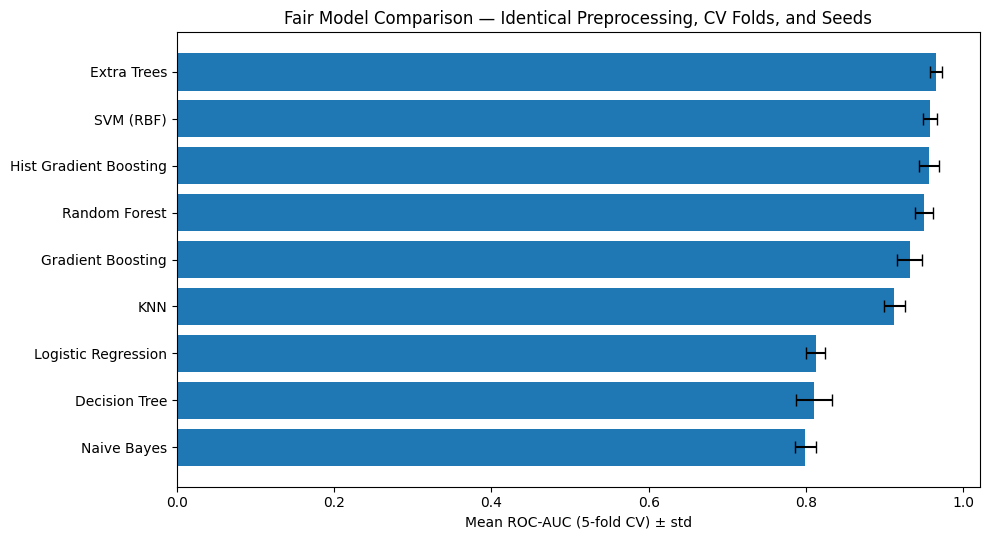

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sorted_table = comparison_table.sort_values("roc_auc_mean")
ax.barh(sorted_table["model"], sorted_table["roc_auc_mean"], xerr=sorted_table["roc_auc_std"], color="tab:blue", capsize=4)
ax.set_xlabel("Mean ROC-AUC (5-fold CV) ± std")
ax.set_title("Fair Model Comparison — Identical Preprocessing, CV Folds, and Seeds")
plt.tight_layout()
plt.show()


### Common Mistakes
- Comparing models evaluated with **different** `cv` objects (even if both say `cv=5`) — without an explicit shared, seeded `StratifiedKFold` object, each model's `cross_validate()` call would use a *different* random 5-fold split, adding noise to the comparison that has nothing to do with genuine model quality differences.
- Applying scaling to some models in the comparison but not others — even though tree-based models don't *need* it, inconsistent preprocessing across a comparison table undermines the "fair, apples-to-apples" property the whole exercise is meant to provide.
- Reporting only the single best metric column and discarding the rest — hides genuine tradeoffs (e.g., the top ROC-AUC model might have notably worse recall) that a business decision should actually weigh.

### Best Practices
- Build (and reuse across projects) exactly this kind of comparison function: identical preprocessing, identical shared/seeded CV object, multiple metrics, and training time — a genuinely reusable piece of ML engineering infrastructure, not a one-off script.
- Always visualize the comparison (as a sorted bar chart with error bars) alongside the raw table — the Matplotlib course's Chapter 60 pattern, now fed by genuinely fair, leakage-safe Scikit-learn evaluation.

### Interview Insight
**Q: You're comparing 8 candidate models for a new classification project. What specifically makes a comparison "fair," beyond just running `cross_val_score` on each?**
A: Every model needs to be evaluated with (1) identical preprocessing — even models that don't strictly need scaling should get it, so no model is disadvantaged or advantaged by preprocessing differences, (2) the exact same cross-validation fold splits, achieved by passing one shared, seeded `StratifiedKFold` (or equivalent) object to every model's evaluation rather than letting each call generate its own random split, and (3) the same set of evaluation metrics, reported together rather than cherry-picking whichever metric favors a particular model. Without these controls, apparent performance differences between models can partly reflect evaluation noise (different folds, different preprocessing) rather than genuine model quality differences.

### Quiz (Chapter 52)
1. Why must every model in a fair comparison receive an identical shared `cv` object, not just "5-fold CV" in the abstract?
2. Why include tree-based models in a scaled Pipeline even though they don't strictly need scaling?
3. What comparison dimension does `fit_time_total_s` add that pure performance metrics miss?

### Chapter 52 Summary
- A reusable `compare_models()` function — identical preprocessing, identical seeded CV folds, multiple metrics, and training time — is genuine ML engineering infrastructure worth building once and reusing across projects.
- This formalizes and generalizes the informal baseline scan first introduced in Chapter 13, now with the full rigor (fairness controls, multiple metrics, timing) a real project deliverable requires.

---

## END OF NOTEBOOK 9 — What You Should Now Be Able To Do
- Apply `sample_weight` beyond class imbalance — recency weighting, business-importance weighting — at both training and evaluation time.
- Navigate the full interpretability landscape and know precisely which technique (coefficients, `feature_importances_`, permutation importance, partial dependence) answers which question.
- Compute and interpret permutation importance for any model type, including its known correlated-feature limitation.
- Build and interpret Partial Dependence and ICE plots, and explain why they show model behavior, not causation.
- Use `LearningCurveDisplay` and `ValidationCurveDisplay` to empirically confirm bias/variance diagnoses and hyperparameter tradeoffs across every model family covered so far.
- Build a genuinely fair, reusable multi-model comparison framework with identical preprocessing, shared CV folds, multiple metrics, and training-time tracking.

## Before Moving to Notebook 10 (Chapters 53–60: Model Selection Strategy, Time Series Validation, Grouped Data, Data Leakage (full module), Pipeline Debugging, Model Inspection, Feature Names, Random State & Reproducibility)

